### Business Problem:

#### A global e-commerce company operating across multiple regions manages end-to-end order fulfillment, including shipping and delivery, for products. The company is facing inconsistent delivery performance, where actual shipping times often deviate from scheduled timelines, leading to unpredictable order profitability.

### Desired Outcome:

#### The goal is to analyze delivery operations, identify bottlenecks, and build a predictive system to reduce delays, optimize shipping decisions, and improve profitability and efficiency.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [5]:
# Set professional color theme
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("viridis")

viridis_colors = cm.viridis(np.linspace(0, 1, 5))
primary_color = viridis_colors[0]
secondary_color = viridis_colors[1]
accent_color = viridis_colors[2]
danger_color = '#800000'
neutral_color = viridis_colors[4]
custom_palette = viridis_colors

In [7]:
df = pd.read_csv('Downloads/DataCoSupplyChainDataset.csv', encoding='latin-1')

In [9]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

#### Exploratory Data Analysis (EDA) 

In [12]:
print('rows, cols:', df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum duplicate:', df.duplicated().sum())
print('\nMissing value (top 20):')
print(df.isna().sum().sort_values(ascending = False).head(20))

rows, cols: (180519, 53)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [14]:
columns_to_drop = [
    'Product Description',
    'Product Image',
    'Customer Email',
    'Customer Password',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Order Zipcode',
    'Longitude',
    'Latitude',
    'Order Item Cardprod Id',
    'Order Item Id',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'Order Item Total',
    'Category Id',
    'Department Id',
    'Order Id',
    'Order Customer Id',
    'Customer Id',
    'Product Card Id',
    'Product Category Id',
    'Benefit per order',  # identical to Order Profit Per Order
    'Product Status',  # have only one value
    'Order City',
    'Order Country',
    'Order State',
    'Customer State',
]

# dropping columns that are either fully missing, redundant, or have only one value (and thus no variance)
df = df.drop(columns=columns_to_drop)

# removing canceled orders since they are not relevant for delivery time analysis and may have different patterns than completed orders
df = df[df['Delivery Status'] != 'Shipping canceled']

# Standard date conversion
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)

# after data cleaning, let's check the overview again to see how the dataset has changed
print('rows, cols:', df.shape)
print('\nMissing values (top 5):')
print(df.isna().sum().sort_values(ascending=False).head(5))

rows, cols: (172765, 22)

Missing values (top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


In [15]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Segment,...,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,Consumer,...,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,Consumer,...,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,Consumer,...,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,Home Office,...,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,Corporate,...,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [16]:
# value counts for categorical columns with low cardinality
for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n{col}, value counts:')
        print(df[col].value_counts())


Type, value counts:
Type
DEBIT       69295
TRANSFER    42129
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real), value counts:
Days for shipping (real)
2    54205
6    27489
3    27478
4    27297
5    27003
0     4839
1     4454
Name: count, dtype: int64

Days for shipment (scheduled), value counts:
Days for shipment (scheduled)
4    103153
2     33806
1     26513
0      9293
Name: count, dtype: int64

Delivery Status, value counts:
Delivery Status
Late delivery       98977
Advance shipping    41592
Shipping on time    32196
Name: count, dtype: int64

Late_delivery_risk, value counts:
Late_delivery_risk
1    98977
0    73788
Name: count, dtype: int64

Customer Country, value counts:
Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64

Customer Segment, value counts:
Customer Segment
Consumer       89420
Corporate      52528
Home Office    30817
Name: count, dtype: int64

Market, value counts:
Market
LATAM         

In [17]:
# calculating order processing time and delay
df['Order Processing Time'] = (
    df['shipping date (DateOrders)'] - df['order date (DateOrders)']
)
df['Delay'] = df['Order Processing Time'] - pd.to_timedelta(
    df['Days for shipment (scheduled)'], unit='D'
)
df['Is_Delayed'] = df['Delay'] > pd.Timedelta(0)
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_day'] = df['order date (DateOrders)'].dt.day_name()
df['order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,order_month,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765,172765,172765,172765.000000,172765.000000
mean,3.498596,2.933100,183.165948,0.572900,2016-06-12 15:25:39.457991,0.120801,203.828493,22.032360,141.278595,2016-06-16 03:25:14.452927,3 days 11:59:34.994935,0 days 13:35:55.165687,6.235511,11.482604
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0 days 12:00:00,-2 days +00:00:00,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 18:01:00,0.080000,119.980003,7.030000,50.000000,2015-09-25 08:59:00,2 days 00:00:00,0 days 00:00:00,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 08:11:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 03:38:00,3 days 00:00:00,1 days 00:00:00,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-02-28 21:08:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 08:00:00,5 days 00:00:00,1 days 00:00:00,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6 days 00:00:00,4 days 00:00:00,12.000000,23.000000
std,1.623446,1.373405,120.141871,0.494659,NaN,0.466610,132.392520,104.355313,139.862956,NaN,1 days 14:48:49.033909,1 days 11:43:42.182276,3.405593,6.927276


In [20]:
df['Is_Delayed'].value_counts()


Is_Delayed
True     103816
False     68949
Name: count, dtype: int64

In [22]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer City', 'Customer Country',
       'Customer Segment', 'Department Name', 'Market',
       'order date (DateOrders)', 'Order Item Profit Ratio', 'Sales',
       'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'order_month', 'order_day', 'order_hour'],
      dtype='str')

In [23]:
# First we find profit how much profit make and how much they are in loss

In [25]:
# Profitability Flag based on Order Profit Per Order
df['Profitability Flag'] = np.select(
    [df['Order Profit Per Order'] > 0, df['Order Profit Per Order'] < 0],
    ['Profit', 'Loss'],
    default='Break-even', #break-even is neither loss nor profit 
)
df['Profitability Flag'].value_counts()

Profitability Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64

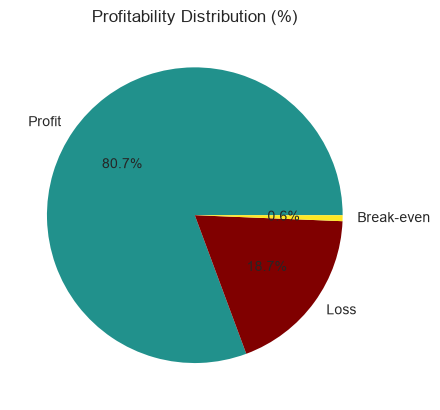

In [26]:
# visualization of profitability distribution
profit_counts = df['Profitability Flag'].value_counts(normalize=True) * 100
profit_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=[accent_color, danger_color, neutral_color],
)
plt.ylabel('')
plt.title('Profitability Distribution (%)')
plt.show()

In [34]:
def format_func(value):
  if value >= 1e6:
    return f'{value/1e6:.1f}M $'
  elif value >= 1e3:
    return f'{value/1e3:.1f}K $'
  else:
    return f'{value:.0f} $'


delayed_df = df[df['Delay'] > pd.Timedelta(0)]

metrics = {}
metrics['Total Orders'] = len(df)
metrics['Late Deliveries'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %'] = (
    1 - float(metrics['Late Deliveries']) / metrics['Total Orders']
) * 100
metrics['Late Delivery %'] = (
    float(metrics['Late Deliveries']) / metrics['Total Orders']
) * 100
metrics['Total Profit'] = format_func(
    df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum()
)
metrics['Total Loss due to delays'] = format_func(
    df.loc[df['Delay'] > pd.Timedelta(0), 'Order Profit Per Order'].sum()
)

print('\n--- Business KPIs ---\n')
for k, v in metrics.items():
  if isinstance(v, float):
    print(f'{k}: {v:.2f}')
  else:
    print(f'{k}: {v}')


--- Business KPIs ---

Total Orders: 172765
Late Deliveries: 103816
90% Delay (days): 3 days 00:00:00
On time Delivery %: 39.91
Late Delivery %: 60.09
Total Profit: 7.5M $
Total Loss due to delays: 2.2M $


### Profitablity & Delivery Time Analysis

In [38]:
#It would be more accurate to convert the delay directly into days and then categorize it as Group B.
df['Delay_Days'] = df['Delay'].dt.days

# Grouping by Delay_Days to get clean aggregated metrics
profit_metrics = (
    df.groupby('Delay_Days')['Order Profit Per Order']
    .agg(
        mean_profit='mean',
        total_profit='sum',
        order_count='count',
    )
    .reset_index()
)

# Rename column for display
profit_metrics = profit_metrics.rename(columns={'Delay_Days': 'Delay'})
profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [45]:
# Convert the delay directly into an integer number of days, so that the time (hours/minutes) is removed and only the days remain.
df['Delay_Days'] = df['Delay'].dt.days

# Print value_counts() 
delay_distribution = (
    df['Delay_Days'].value_counts(normalize=True).sort_index() * 100
).reset_index()
delay_distribution.columns = ['Delay', 'Percentage']

delay_distribution

,Delay,Percentage
0,-2,12.081730
1,-1,11.992591
2,0,21.213788
3,1,30.968657
4,2,15.947096
5,3,3.919775
6,4,3.876364


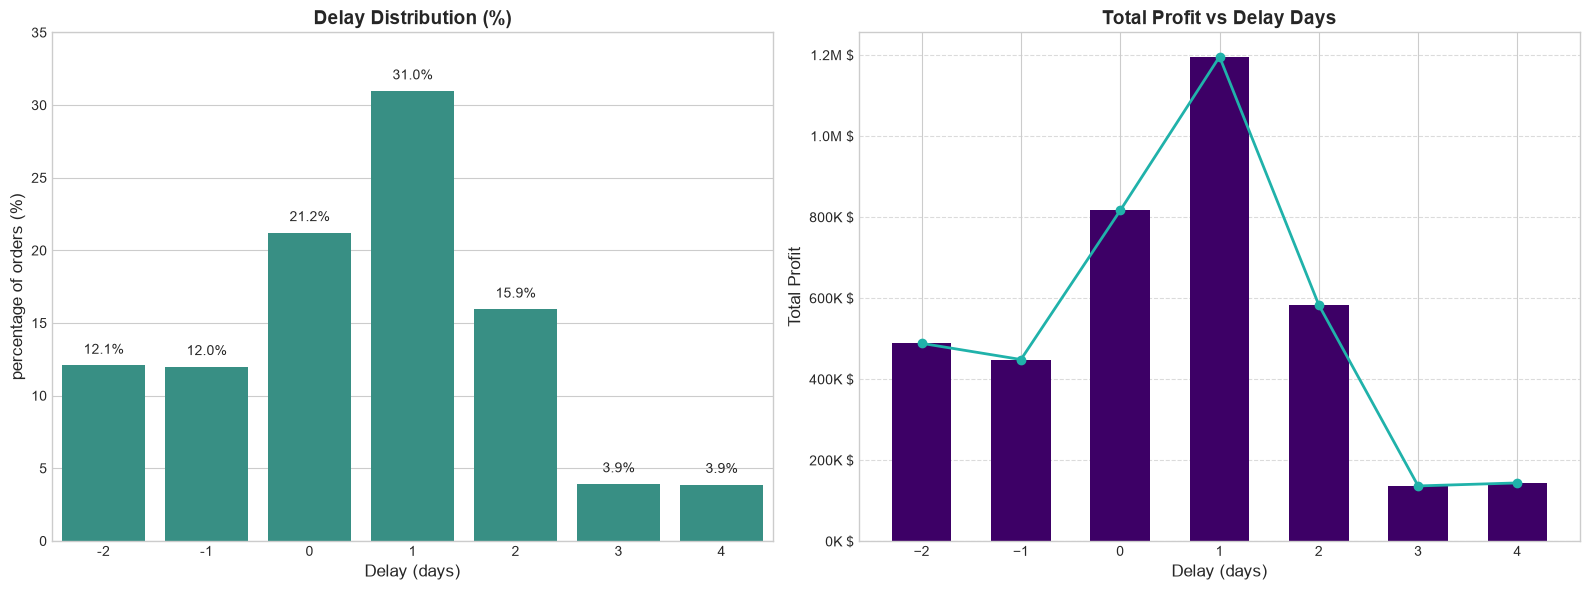

In [48]:
# 1. Clean delay days conversion
df['Delay_Days'] = df['Delay'].dt.days

# 2. Recalculate delay distribution
delay_distribution = (
    df['Delay_Days'].value_counts(normalize=True).sort_index() * 100
).reset_index()
delay_distribution.columns = ['Delay', 'Percentage']

# 3. Recalculate profit metrics
profit_metrics = (
    df.groupby('Delay_Days')['Order Profit Per Order']
    .agg(mean_profit='mean', total_profit='sum', order_count='count')
    .reset_index()
)
profit_metrics = profit_metrics.rename(columns={'Delay_Days': 'Delay'})

# 4. Plotting dual-style charts matching the video tutorial
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- 1st Subplot: Delay Distribution (%) ---
sns.barplot(
    x='Delay', y='Percentage', data=delay_distribution, color='#2a9d8f', ax=ax1
)
ax1.set_title('Delay Distribution (%)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Delay (days)', fontsize=12)
ax1.set_ylabel('percentage of orders (%)', fontsize=12)
ax1.set_ylim(0, 35)

for bar in ax1.patches:
  height = bar.get_height()
  if height > 0:
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.6,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
    )

# --- 2nd Subplot: Total Profit vs Delay Days (Bar + Line Overlay) ---
ax2.bar(
    profit_metrics['Delay'],
    profit_metrics['total_profit'],
    color='#3d0066',
    width=0.6,
    label='Total Profit (Bars)',
)
ax2.set_title('Total Profit vs Delay Days', fontsize=14, fontweight='bold')
ax2.set_xlabel('Delay (days)', fontsize=12)
ax2.set_ylabel('Total Profit', fontsize=12)

# Adding the trend line overlay on secondary style / same axis
ax2.plot(
    profit_metrics['Delay'],
    profit_metrics['total_profit'],
    color='#20b2aa',
    marker='o',
    linewidth=2,
    label='Trend',
)

# Formatting Y-axis with K/M formatting if desired
ax2.yaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: f'{x*1e-6:.1f}M $'
        if x >= 1e6
        else f'{x*1e-3:.0f}K $'
    )
)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Bottlneck Detection 

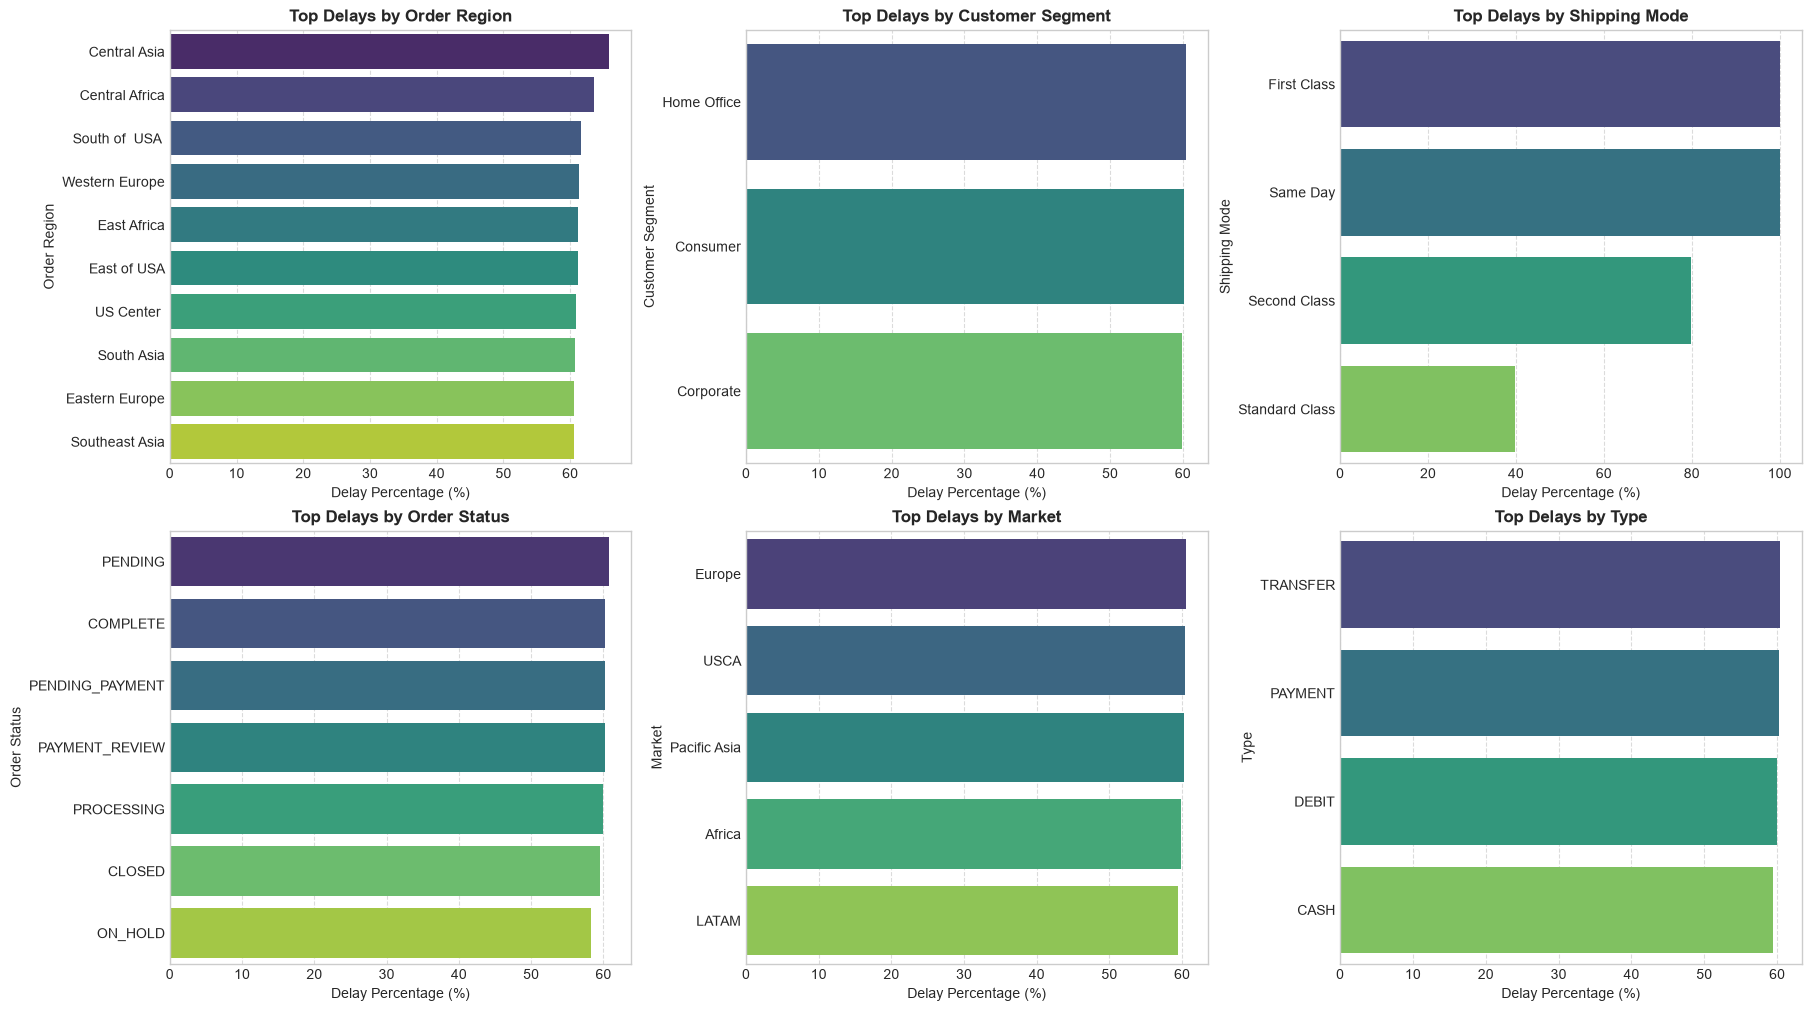

In [49]:
# Function to compute delay percentage by category
def compute_delay_pct_by_category(category):
  cat_df = (
      df.groupby(category)
      .agg(
          total_orders=('Delay', 'count'),
          late_orders=('Is_Delayed', 'sum'),
      )
      .reset_index()
  )
  cat_df['delay_pct'] = (
      cat_df['late_orders'] / cat_df['total_orders']
  ) * 100
  cat_df = cat_df.sort_values('delay_pct', ascending=False).head(10)
  return cat_df


# Categories to analyze for bottlenecks
categories = [
    'Order Region',
    'Customer Segment',
    'Shipping Mode',
    'Order Status',
    'Market',
    'Type',
]

# Setting up subplots grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
axes = axes.flatten()

# Looping through each category and plotting horizontal bar charts
for ax, category in zip(axes, categories):
  cat_df = compute_delay_pct_by_category(category)
  sns.barplot(
      data=cat_df,
      x='delay_pct',
      y=category,
      ax=ax,
      palette='viridis',
      hue=category,
      legend=False,
  )
  ax.set_title(f'Top Delays by {category}', fontsize=12, fontweight='bold')
  ax.set_xlabel('Delay Percentage (%)', fontsize=10)
  ax.set_ylabel(category, fontsize=10)
  ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

### Root Cause Analysis

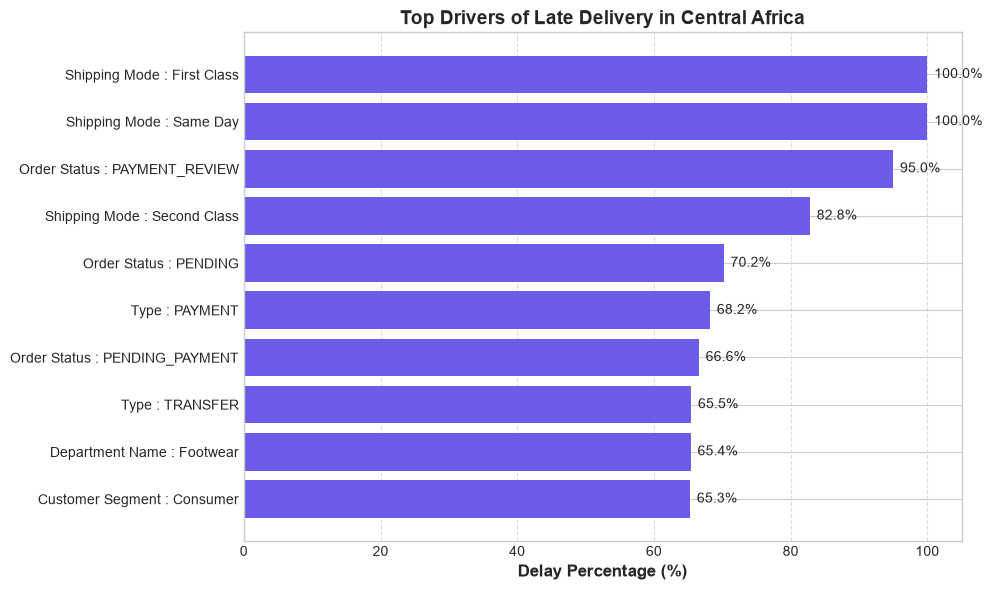

In [52]:
def top_drivers_for_region(region):
  df_region = df[df['Order Region'] == region].copy()

  drivers = [
      'Shipping Mode',
      'Customer Segment',
      'Department Name',
      'Type',
      'Order Status',
  ]

  all_factors = []
  for factor in drivers:
    temp = (
        df_region.groupby(factor)
        .agg(
            total_orders=('Delay', 'count'),
            late_orders=('Is_Delayed', 'sum'),
            avg_delay=('Delay', 'mean'),
        )
        .reset_index()
    )

    temp['delay_pct'] = (temp['late_orders'] / temp['total_orders']) * 100
    temp['Driver'] = factor
    temp['Factor_Level'] = factor + ' : ' + temp[factor].astype(str)

    all_factors.append(
        temp[['Driver', 'Factor_Level', 'delay_pct', 'avg_delay', 'total_orders']]
    )

  # Combine all drivers
  final_df = pd.concat(all_factors)
  return final_df


# 1. First call the function for 'Central Africa' (or 'Southeast Asia' as shown in your video)
region_name = 'Central Africa'
final_df = top_drivers_for_region(region_name)

# 2. Extract Top 10 drivers from the returned dataframe
top_factors = final_df.sort_values('delay_pct', ascending=False).head(10)

# 3. Plotting the horizontal bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_factors['Factor_Level'],
    top_factors['delay_pct'],
    color='#6c5ce7',
)
plt.xlabel('Delay Percentage (%)', fontsize=12, fontweight='bold')
plt.title(
    f'Top Drivers of Late Delivery in {region_name}',
    fontsize=14,
    fontweight='bold',
)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Adding exact percentage text on bars
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 1,
      bar.get_y() + bar.get_height() / 2,
      f'{width:.1f}%',
      va='center',
      fontsize=10,
  )

plt.tight_layout()
plt.show()

### Time Based Analysis

In [57]:
# Delay % by Month, Day of Week, Hour

delay_by_month = (
    df.groupby('order_month')['Is_Delayed'].mean().reset_index()
)
delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100

delay_by_day = df.groupby('order_day')['Is_Delayed'].mean().reset_index()
delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100

delay_by_hour = df.groupby('order_hour')['Is_Delayed'].mean().reset_index()
delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

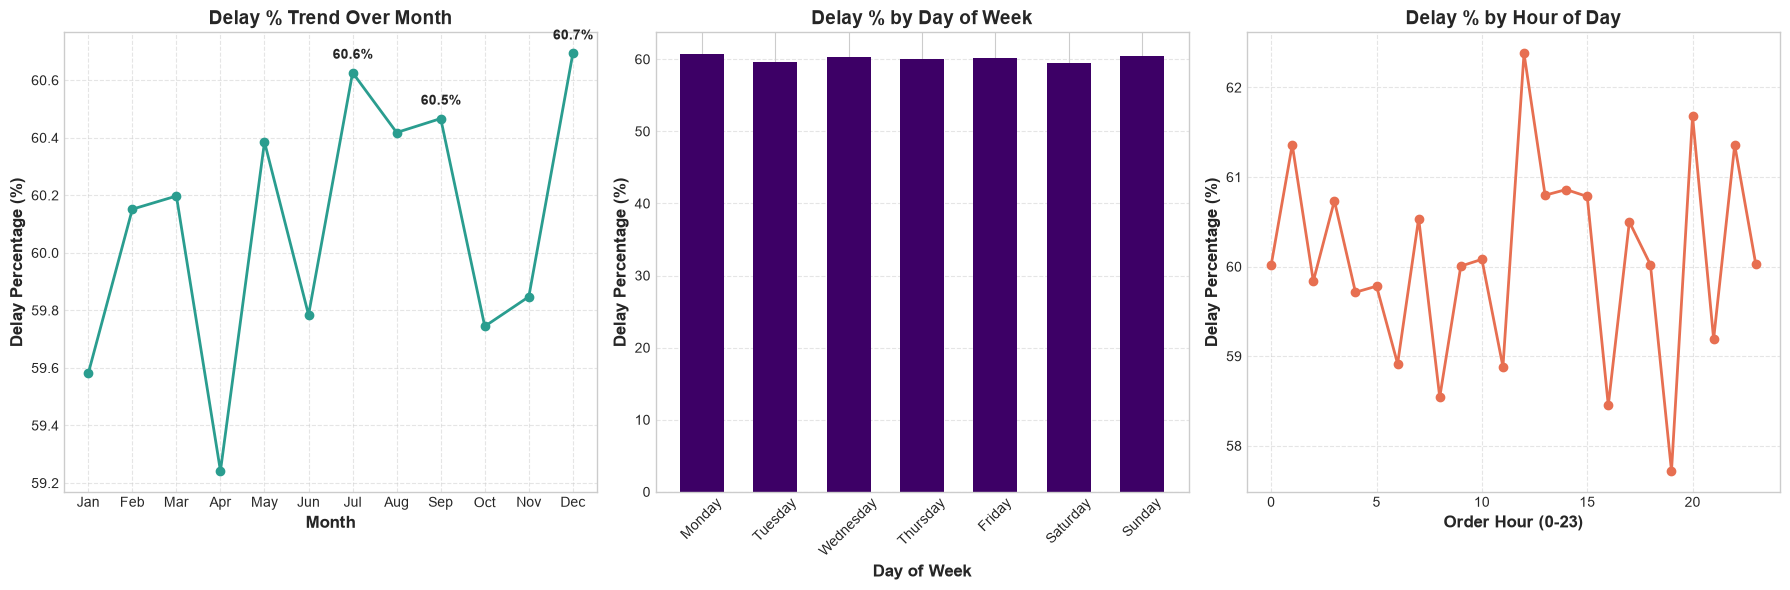

In [59]:
# Subplots for Time Series Analysis (Month, Day of Week, Hour)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

# --- Subplot 1: Delay % Trend Over Month ---
ax1.plot(
    delay_by_month['order_month'],
    delay_by_month['delay_pct'],
    marker='o',
    color='#2a9d8f',
    linewidth=2,
)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels([
    'Jan',
    'Feb',
    'Mar',
    'Apr',
    'May',
    'Jun',
    'Jul',
    'Aug',
    'Sep',
    'Oct',
    'Nov',
    'Dec',
])
ax1.set_xlabel('Month', fontsize=12, fontweight='bold')
ax1.set_ylabel('Delay Percentage (%)', fontsize=12, fontweight='bold')
ax1.set_title('Delay % Trend Over Month', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# Annotate top 3 highest months
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
  ax1.annotate(
      f"{row['delay_pct']:.1f}%",
      (row['order_month'], row['delay_pct']),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=10,
      fontweight='bold',
  )

# --- Subplot 2: Delay % by Day of Week ---
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
delay_by_day['order_day'] = pd.Categorical(
    delay_by_day['order_day'], categories=day_order, ordered=True
)
delay_by_day = delay_by_day.sort_values('order_day')

ax2.bar(
    delay_by_day['order_day'],
    delay_by_day['delay_pct'],
    color='#3d0066',
    width=0.6,
)
ax2.set_xticklabels(delay_by_day['order_day'], rotation=45)
ax2.set_xlabel('Day of Week', fontsize=12, fontweight='bold')
ax2.set_ylabel('Delay Percentage (%)', fontsize=12, fontweight='bold')
ax2.set_title('Delay % by Day of Week', fontsize=14, fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# --- Subplot 3: Delay % by Hour ---
ax3.plot(
    delay_by_hour['order_hour'],
    delay_by_hour['delay_pct'],
    marker='o',
    color='#e76f51',
    linewidth=2,
)
ax3.set_xlabel('Order Hour (0-23)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Delay Percentage (%)', fontsize=12, fontweight='bold')
ax3.set_title('Delay % by Hour of Day', fontsize=14, fontweight='bold')
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Machine Learning Model

In [64]:
!pip install imbalanced-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [65]:
from collections import Counter
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
!pip install imbalanced-learn

# 1. Feature Selection for ML Model
features = [
    'Days for shipment (scheduled)',
    'Sales per customer',
    'Sales',
    'Order Profit Per Order',
    'Product Price',
    'order_month',
    'order_hour',
]
X = df[features]
y = df['Is_Delayed'].astype(int)

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Handling Imbalanced Data using SMOTE
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# 4. Training Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_sm, y_train_sm)

# 5. Predictions & Evaluation
y_pred = rf_model.predict(X_test)

print('--- Model Evaluation ---')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'Precision: {precision_score(y_test, y_pred):.4f}')
print(f'Recall: {recall_score(y_test, y_pred):.4f}')
print('\nClassification Report:\n', classification_report(y_test, y_pred))


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


--- Model Evaluation ---
Accuracy: 0.6966
Precision: 0.7962
Recall: 0.6655

Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.74      0.66     13785
           1       0.80      0.67      0.73     20768

    accuracy                           0.70     34553
   macro avg       0.70      0.70      0.69     34553
weighted avg       0.72      0.70      0.70     34553

